# Ananya Gupta — Final Contribution Notebook

**EPFL MNLP Open Project · AudioLLM-D · ID 390080**

This notebook summarises my individual contribution: dataset pipeline & CHAT parsing, disfluency-aware DoRA fine-tuning, decode-time inference analysis, and audio QA evaluation. All bundled metrics live in `ananya_data/`.

## 1 · Contribution summary

| Area | What I did | Why it matters |
|---|---|---|
| **Data & parsing** | CHAT parser improvements, participant audio extraction, disfluency token design | Clean, clinically meaningful training targets |
| **Split design** | Speaker-disjoint 80/20 split on `source_id` | Prevents leakage across train/test |
| **Fine-tuning** | DoRA setup & runs on Qwen2-Audio with disfluency-aware loss | Parameter-efficient adaptation to PwD speech |
| **Inference analysis** | Logit-bias sweep tooling + per-step token probability tracing | Diagnose *why* the model under-emits disfluencies |
| **QA evaluation** | Compared audio-only vs audio+transcript QA input modes on 672 questions | Tests whether disfluency transcription helps downstream reasoning |

In [1]:
import subprocess
import sys
from pathlib import Path

# Install the project package from the repo (notebooks/../AudioLLM-D).
AUDIOLLM_D_DIR = (Path("..") / "AudioLLM-D").resolve()
if not (AUDIOLLM_D_DIR / "pyproject.toml").exists():
    raise FileNotFoundError(
        f"Expected AudioLLM-D at {AUDIOLLM_D_DIR}. "
        "Run this notebook with working directory set to notebooks/."
    )

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", str(AUDIOLLM_D_DIR)],
    check=True,
)
print(f"Installed audiollm-d from {AUDIOLLM_D_DIR}")

!pip install matplotlib

Obtaining file:///scratch/ananya/open-project-m2-lordofthestrings/AudioLLM-D
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for audiollm-d (pyproject.toml): started
  Building editable for audiollm-d (pyproject.toml): finished with status 'done'
  Created wheel for audiollm-d: filename=audiollm_d-0.1.0-0.editable-py3-none-any.whl size=3013 sha256=133801fb95c2a7192f0a0393ecf1efde562c0c43f415a5f09602d9535f9c92df
  Stored in directory: /tmp/pip-ephem-wheel-cache-itngormp/wheels/f5/b1/fe/2b2df3528c9078608a5deaaa342f40e7765dc329e2

In [2]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

# Paths relative to this notebook (cwd should be notebooks/)
NOTEBOOK_DIR = Path(".").resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent
DATA_DIR = NOTEBOOK_DIR / "ananya_data"
DATA_ROOT = DATA_DIR / "manifests"
ANANYA_DIR = PROJECT_ROOT / "ananya"
AUDIOLLM_SRC = PROJECT_ROOT / "AudioLLM-D" / "src"
SCRIPTS_DIR = PROJECT_ROOT / "AudioLLM-D" / "scripts"
sys.path[:0] = [str(ANANYA_DIR), str(AUDIOLLM_SRC), str(SCRIPTS_DIR)]

DISFLUENCY_TOKENS = [
    "[short-pause]", "[medium-pause]", "[long-pause]",
    "[unclear-speech]", "[laughter]", "[non-verbal]", "[uh]", "[um]",
]
TOKEN_SHORT = {
    "[short-pause]": "short-pause", "[medium-pause]": "med-pause",
    "[long-pause]": "long-pause", "[unclear-speech]": "unclear",
    "[laughter]": "laugh", "[non-verbal]": "non-verbal",
    "[uh]": "[uh]", "[um]": "[um]",
}

## 2 · Dataset pipeline & split validation

The merged DementiaBank corpus passes through three stages:

| Stage | Location | Role |
|---|---|---|
| **Raw** | `merged_data_raw/` | Original audio + CHAT `.cha` transcripts |
| **Processed** | `merged_data_processed/` | Participant clips + normalised text |
| **80/20 split** | `ananya_data/manifests/` | Speaker-disjoint train/test manifests for fine-tuning |

Below: split balance, zero speaker leakage, diagnosis mix, and disfluency-token frequency (read-only).

Speaker overlap across splits (must be 0): 0


,split,clips,speakers,fraction
0,train,658,154,79.7%
1,test,168,51,20.3%



Diagnosis distribution:


split,test,train
diagnosis,,
Alzheimer's,5,22
Aphasia,0,2
Conrol,0,2
Control,15,38
Dementia,3,7
MCI,0,3
Memory,0,4
PPA,0,39
PPA-NOS,0,61


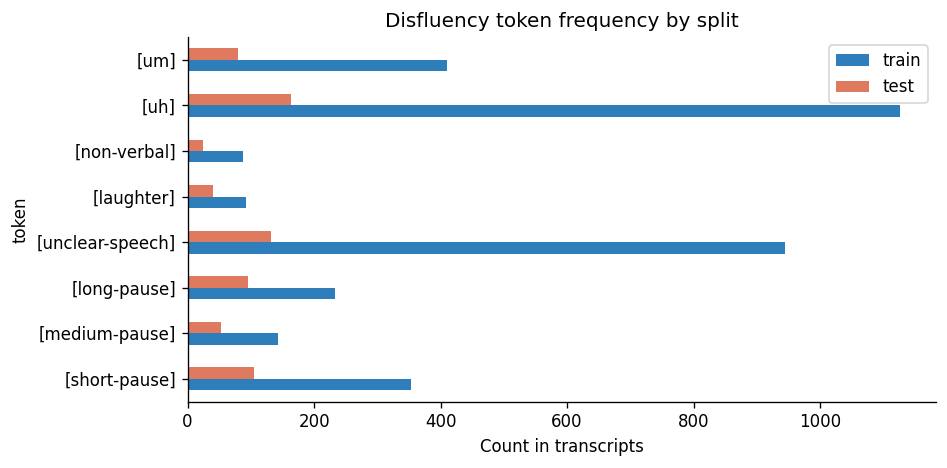


Manifest schema: ['age', 'audio_path', 'clip_id', 'clip_index', 'diagnosis', 'mmse', 'sex', 'source_id', 'split', 'text', 'transcript_path']
Example clip: AMR6628a_000 | source: AMR6628a
Example text: okay [um] [long-pause] this is the [long-pause] Cinderella , yes. and these are the stepmothers. oh , and they went to the ball for the [long-pause] and she hadta stay at home. and so they're going an ...


In [3]:
def load_manifest(path: Path) -> list[dict]:
    rows = []
    with path.open(encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows

manifests = {
    split: load_manifest(DATA_ROOT / split / "manifest.jsonl")
    for split in ("train", "test")
}

train_sources = {r["source_id"] for r in manifests["train"]}
test_sources = {r["source_id"] for r in manifests["test"]}
overlap = train_sources & test_sources
n_total = len(manifests["train"]) + len(manifests["test"])

split_df = pd.DataFrame([
    {
        "split": s,
        "clips": len(manifests[s]),
        "speakers": len({r["source_id"] for r in manifests[s]}),
        "fraction": len(manifests[s]) / n_total,
    }
    for s in ("train", "test")
])
print(f"Speaker overlap across splits (must be 0): {len(overlap)}")
display(split_df.style.format({"fraction": "{:.1%}"}))

# diagnosis mix
diag_rows = []
for split, rows in manifests.items():
    for diagnosis, count in Counter(r.get("diagnosis") or "unknown" for r in rows).most_common():
        diag_rows.append({"split": split, "diagnosis": diagnosis, "clips": count})
diag_df = pd.DataFrame(diag_rows)
print("\nDiagnosis distribution:")
display(diag_df.pivot(index="diagnosis", columns="split", values="clips").fillna(0).astype(int))

# disfluency token counts
def token_counts(rows):
    c = Counter()
    for row in rows:
        for tok in DISFLUENCY_TOKENS:
            c[tok] += row["text"].count(tok)
    return c

tok_df = pd.DataFrame({
    "token": DISFLUENCY_TOKENS,
    "train": [token_counts(manifests["train"])[t] for t in DISFLUENCY_TOKENS],
    "test": [token_counts(manifests["test"])[t] for t in DISFLUENCY_TOKENS],
}).set_index("token")
tok_df.plot(kind="barh", figsize=(8, 4), color=["#2f7ebc", "#e07a5f"])
plt.xlabel("Count in transcripts")
plt.title("Disfluency token frequency by split")
plt.tight_layout()
plt.show()

sample = manifests["train"][0]
print("\nManifest schema:", sorted(sample.keys()))
print("Example clip:", sample.get("clip_id"), "| source:", sample.get("source_id"))
print("Example text:", sample.get("text", "")[:200], "...")

### Dataset insights (aligned with final report)

- **826 clips** across **201 participants** (~5.45 h) from merged DementiaBank corpora (ADReSS + Lu, Hopkins, DePaul, Kempler).
- Disfluency tokens account for **~10%** of all reference tokens; `[uh]` and `[unclear-speech]` dominate, while `[laughter]` and `[non-verbal]` each appear in **<0.6%** of tokens on test.
- This heavy class imbalance motivates **inverse-frequency token weighting** and **focal loss** on the rarest brackets in team training runs.
- Speaker-disjoint splitting (zero overlap above) prevents leakage; diagnosis mix is preserved across train/test.

In [4]:
# Report Table 1: disfluency token share of all reference tokens
def token_table(rows):
    total_words = sum(len(r["text"].split()) for r in rows)
    rows_out = []
    for tok in DISFLUENCY_TOKENS:
        n = sum(r["text"].count(tok) for r in rows)
        rows_out.append({"token": tok, "count": n, "pct": 100 * n / total_words})
    return pd.DataFrame(rows_out), total_words

train_tbl, train_words = token_table(manifests["train"])
test_tbl, test_words = token_table(manifests["test"])
pct_df = train_tbl[["token", "pct"]].rename(columns={"pct": "train (%)"}).merge(
    test_tbl[["token", "pct"]].rename(columns={"pct": "test (%)"}), on="token"
)
pct_df["train count"] = train_tbl["count"].values
pct_df["test count"] = test_tbl["count"].values
display(pct_df.set_index("token").style.format({
    "train (%)": "{:.2f}", "test (%)": "{:.2f}"
}).set_caption(
    f"Disfluency vocabulary frequency (train: {train_words:,} tokens; test: {test_words:,} tokens)"
))

print(f"Total corpus: {len(manifests['train']) + len(manifests['test'])} clips, "
      f"{len(train_sources | test_sources)} unique speakers")


,train (%),test (%),train count,test count
token,,,,
[short-pause],1.09,1.52,354,105
[medium-pause],0.44,0.77,143,53
[long-pause],0.72,1.39,233,96
[unclear-speech],2.91,1.91,945,132
[laughter],0.29,0.58,93,40
[non-verbal],0.27,0.35,87,24
[uh],3.47,2.37,1127,164
[um],1.26,1.14,410,79


Total corpus: 826 clips, 205 unique speakers


## 3 · CHAT parser improvements

CHAT transcripts encode speaker tiers, timestamps, fillers (`&-uh`), pauses (`(.)`, `(...)`) and unclear spans. My parser work in `audiollm_d/chat_parser.py` extracts **participant (`PAR`) speech only** and maps CHAT symbols to stable training tokens (`[uh]`, `[short-pause]`, etc.).

The notebook reads a **pre-parsed sample** from `ananya_data/parsed_transcript_sample.json` (Hopkins Cinderella task, participant `BBW8512a`) — no raw `.cha` file is loaded here. Full manifests in `ananya_data/manifests/` contain the same normalised text used for training.

In [15]:
PARSED_SAMPLE_PATH = DATA_DIR / "parsed_transcript_sample.json"
sample = json.loads(PARSED_SAMPLE_PATH.read_text(encoding="utf-8"))

mapping_df = pd.DataFrame(sample["token_mapping_examples"]).set_index("chat_symbol")
display(mapping_df.rename(columns={"token": "training token"}))

print(f"Sample: {sample['source_id']} ({sample['corpus']}, {sample['task']} task)")
print("Participant metadata:", sample["metadata"])

par_lines = [u["text"] for u in sample["timed_utterances"]["PAR"]]
print(f"\nParsed participant utterances: {len(par_lines)} (showing first 5)")
for line in par_lines[:5]:
    print(" ", line)

timed_par = sample["timed_utterances"]["PAR"]
timed_inv = sample["timed_utterances"]["INV"]
print(f"\nTimestamped spans — PAR: {len(timed_par)}, INV: {len(timed_inv)}")
print("\nFirst 4 PAR spans (used for participant-only audio clipping):")
for item in timed_par[:4]:
    print(f"  {item['start_ms']:>6}–{item['end_ms']:<6} ms | {item['text']}")

print("\nFull normalised transcript (first 300 chars):")
print(sample["participant_transcript"][:300], "...")

,training token
chat_symbol,
&-uh,[uh]
&-um,[um]
(.),[short-pause]
(..),[medium-pause]
(...),[long-pause]
(xxx),[unclear-speech]
&=laughs,[laughter]
&=inhales,[non-verbal]


Sample: BBW8512a (Hopkins, Cinderella task)
Participant metadata: {'language': 'eng', 'corpus': 'Hopkins', 'speaker': 'PAR', 'age': '68;00.', 'sex': 'male', 'diagnosis': 'nfaPPA', 'role': 'Participant'}

Parsed participant utterances: 8 (showing first 5)
  [uh] this is Cinderella.
  those are her two stepsisters and the wicked stepmother.
  [non-verbal] and [um] [medium-pause] she:'s washing the floor.
  [uh] because [uh] [short-pause] the wicked stepsisters and stepmother [um] [short-pause] tell her what to do.
  and [um] [long-pause] let's see [long-pause]

Timestamped spans — PAR: 8, INV: 1

First 4 PAR spans (used for participant-only audio clipping):
    9731–11896  ms | [uh] this is Cinderella.
   12279–16249  ms | those are her two stepsisters and the wicked stepmother.
   17855–27702  ms | [non-verbal] and [um] [medium-pause] she:'s washing the floor.
   28885–41114  ms | [uh] because [uh] [short-pause] the wicked stepsisters and stepmother [um] [short-pause] tell her what to d

## 4 · DoRA fine-tuning results

Before/after metrics from my DoRA run on the speaker-disjoint split. The model learns to emit fillers and pauses, but rare tokens (`[non-verbal]`, `[laughter]`) remain difficult.

In [6]:
DORA_METRICS_PATH = DATA_DIR / "dora" / "pre_post_train_eval_metrics.json"
dora = json.loads(DORA_METRICS_PATH.read_text(encoding="utf-8"))

def d_metrics(stage, split):
    return dora[stage][split]["disfluency_token_metrics"]

rows = []
for split in ("train", "test"):
    b, a = dora["before_train"][split], dora["after_train"][split]
    bd, ad = d_metrics("before_train", split), d_metrics("after_train", split)
    rows.append({
        "split": split, "n": b["num_samples"],
        "WER before": b["wer"], "WER after": a["wer"],
        "F1 before": bd["disfluency_token_f1"], "F1 after": ad["disfluency_token_f1"],
        "recall after": ad["disfluency_token_recall"],
        "miss rate after": ad["disfluency_token_miss_rate"],
    })
dora_df = pd.DataFrame(rows).set_index("split")
dora_df.style.format({c: "{:.3f}" for c in dora_df.columns if c != "n"}).set_caption("DoRA: before vs after training")

,n,WER before,WER after,F1 before,F1 after,recall after,miss rate after
split,,,,,,,
train,658,0.488,0.144,0.000,0.738,0.674,0.326
test,168,0.575,0.365,0.000,0.452,0.452,0.548


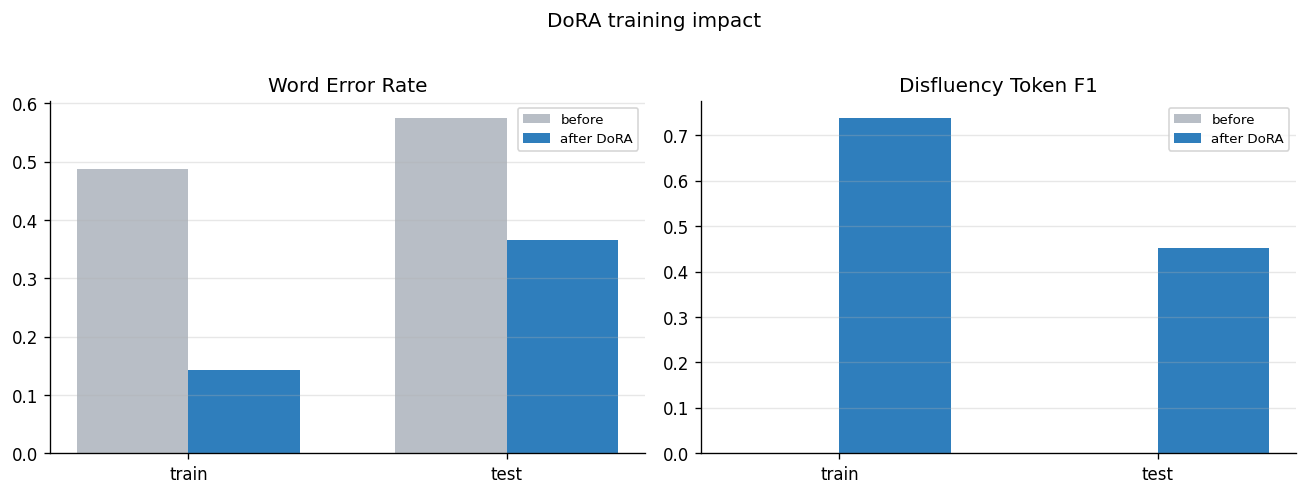

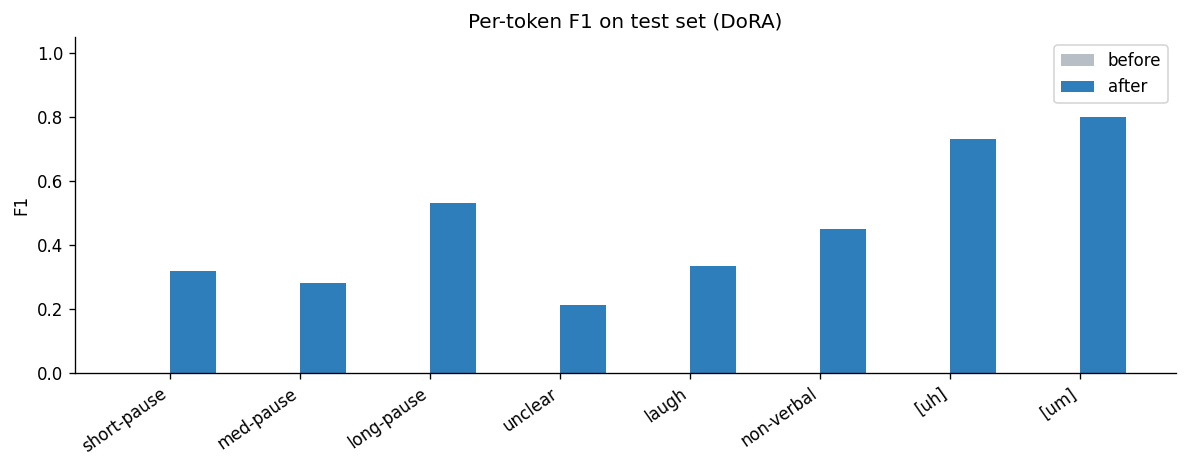

DoRA test — count F1: 0.452 (train 0.738); order-aware F1: 0.330
Train–test F1 gap: 0.287  (same overfitting pattern as team LoRA runs)


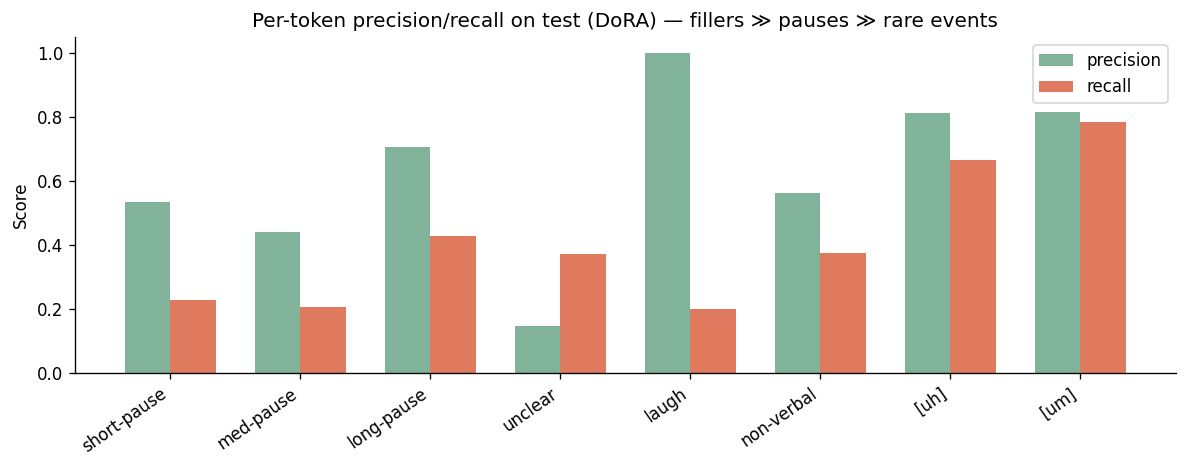

Highest recall: [um] (0.78); lowest: [laughter] (0.20)
[unclear-speech] shows high miss rate + over-generation (precision << recall on test).


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
splits = ["train", "test"]
x = np.arange(2)
w = 0.35

for ax, metric, title in [
    (axes[0], "wer", "Word Error Rate"),
    (axes[1], None, "Disfluency Token F1"),
]:
    if metric == "wer":
        before = [dora["before_train"][s]["wer"] for s in splits]
        after = [dora["after_train"][s]["wer"] for s in splits]
    else:
        before = [d_metrics("before_train", s)["disfluency_token_f1"] for s in splits]
        after = [d_metrics("after_train", s)["disfluency_token_f1"] for s in splits]
    ax.bar(x - w/2, before, w, label="before", color="#b8bec6")
    ax.bar(x + w/2, after, w, label="after DoRA", color="#2f7ebc")
    ax.set_xticks(x); ax.set_xticklabels(splits)
    ax.set_title(title); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)

plt.suptitle("DoRA training impact", y=1.02)
plt.tight_layout()
plt.show()

# per-token F1 on test
before_tok = d_metrics("before_train", "test")["per_token_stats"]
after_tok = d_metrics("after_train", "test")["per_token_stats"]
labels = [TOKEN_SHORT[t] for t in DISFLUENCY_TOKENS]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w/2, [before_tok[t]["f1"] for t in DISFLUENCY_TOKENS], w, label="before", color="#b8bec6")
ax.bar(x + w/2, [after_tok[t]["f1"] for t in DISFLUENCY_TOKENS], w, label="after", color="#2f7ebc")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_ylim(0, 1.05); ax.set_ylabel("F1"); ax.legend()
ax.set_title("Per-token F1 on test set (DoRA)")
plt.tight_layout(); plt.show()

# Order-aware F1 + report-style error hierarchy on DoRA test set
oa_before = d_metrics("before_train", "test")["disfluency_token_order_f1"]
oa_after = d_metrics("after_train", "test")["disfluency_token_order_f1"]
train_f1 = d_metrics("after_train", "train")["disfluency_token_f1"]
test_f1 = d_metrics("after_train", "test")["disfluency_token_f1"]

print(f"DoRA test — count F1: {test_f1:.3f} (train {train_f1:.3f}); order-aware F1: {oa_after:.3f}")
print(f"Train–test F1 gap: {train_f1 - test_f1:.3f}  (same overfitting pattern as team LoRA runs)")

# Per-token recall on test (after DoRA) — mirrors report appendix hierarchy
recall_after = [after_tok[t]["recall"] for t in DISFLUENCY_TOKENS]
prec_after = [after_tok[t]["precision"] for t in DISFLUENCY_TOKENS]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w/2, prec_after, w, label="precision", color="#81b29a")
ax.bar(x + w/2, recall_after, w, label="recall", color="#e07a5f")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_ylim(0, 1.05); ax.set_ylabel("Score"); ax.legend()
ax.set_title("Per-token precision/recall on test (DoRA) — fillers ≫ pauses ≫ rare events")
plt.tight_layout(); plt.show()

best_tok = max(zip(DISFLUENCY_TOKENS, recall_after), key=lambda p: p[1])
worst_tok = min(zip(DISFLUENCY_TOKENS, recall_after), key=lambda p: p[1])
print(f"Highest recall: {best_tok[0]} ({best_tok[1]:.2f}); lowest: {worst_tok[0]} ({worst_tok[1]:.2f})")
print("[unclear-speech] shows high miss rate + over-generation (precision << recall on test).")


### Team fine-tuning progression (final report)

My DoRA run above is an individual replication on the same split. The **team's best LoRA recipe** (synthetic data + focal loss on rare tokens + full encoder adaptation) reaches **WER 0.334**, **count F1 0.572**, and **order-aware F1 0.422** on the held-out 168-clip test set — outperforming Whisper (0.51) and CrisperWhisper (0.47) while uniquely emitting the bracketed disfluency vocabulary.

,name,WER,F1,OA-F1
0,Whisper-large-v3,0.514,—,—
1,CrisperWhisper,0.467,—,—
2,Qwen2-Audio (zero-shot),0.540,0.033,0.012
3,Qwen2-Audio (few-shot),0.663,0.029,0.010
4,LLM-only LoRA,0.465,0.475,0.306
5,LLM LoRA + projector,0.490,0.520,0.332
6,Plain LoRA,0.369,0.510,0.375
7,CTC + diff. learning rates,0.471,0.496,0.319
8,Data aug. + weighted loss,0.380,0.552,0.392
9,MFA classifier,0.365,0.513,0.351


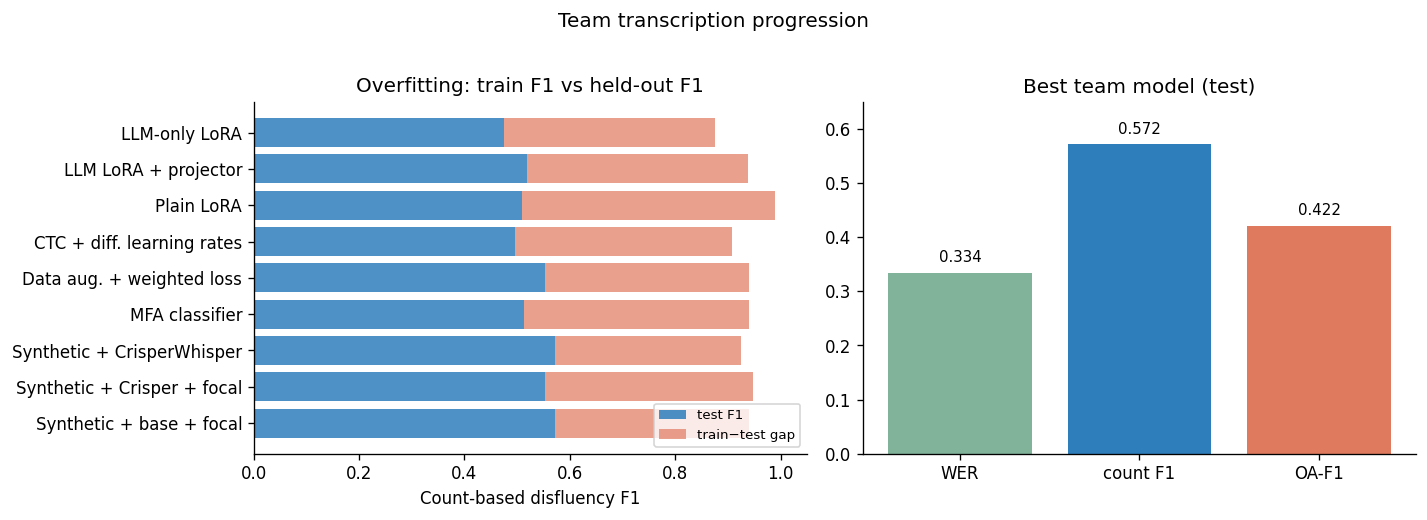

In [8]:
TEAM_RESULTS = json.loads((DATA_DIR / "team_transcription_results.json").read_text())
team_df = pd.DataFrame(TEAM_RESULTS["models"])
prog = team_df[team_df["group"] == "progression"].copy()

display(
    team_df[["name", "test_wer", "test_f1", "test_oa_f1"]]
    .rename(columns={"test_wer": "WER", "test_f1": "F1", "test_oa_f1": "OA-F1"})
    .style.format({"WER": "{:.3f}", "F1": "{:.3f}", "OA-F1": "{:.3f}"}, na_rep="—")
    .background_gradient(subset=["WER"], cmap="RdYlGn_r", vmin=0.33, vmax=0.55)
    .set_caption("Transcription results on held-out test set (from final report)")
)

# Train vs test F1 gap → overfitting
gap = prog.dropna(subset=["train_f1", "test_f1"]).copy()
gap["generalization gap"] = gap["train_f1"] - gap["test_f1"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].barh(gap["name"], gap["test_f1"], color="#2f7ebc", alpha=0.85, label="test F1")
axes[0].barh(gap["name"], gap["generalization gap"], left=gap["test_f1"],
             color="#e07a5f", alpha=0.7, label="train−test gap")
axes[0].set_xlim(0, 1.05)
axes[0].set_xlabel("Count-based disfluency F1")
axes[0].set_title("Overfitting: train F1 vs held-out F1")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].invert_yaxis()

best = prog[prog["name"] == "Synthetic + base + focal"].iloc[0]
axes[1].bar(["WER", "count F1", "OA-F1"],
            [best["test_wer"], best["test_f1"], best["test_oa_f1"]],
            color=["#81b29a", "#2f7ebc", "#e07a5f"])
axes[1].set_ylim(0, 0.65)
axes[1].set_title("Best team model (test)")
for i, v in enumerate([best["test_wer"], best["test_f1"], best["test_oa_f1"]]):
    axes[1].text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)

plt.suptitle("Team transcription progression", y=1.02)
plt.tight_layout()
plt.show()


**Transcription trends (from final report §Results):**

1. **Fine-tuning is essential** — zero/few-shot Qwen2-Audio emits almost no disfluency tokens (F1 ≤ 0.03); external ASR has lower WER but no disfluency vocabulary at all.
2. **Full encoder adaptation matters** — LLM-only LoRA (WER 0.46) improves over the base model, but adapting the full stack (plain LoRA, WER 0.37) unlocks much stronger disfluency recovery.
3. **Largest single gain: data aug + inverse token weighting** — F1 rises from 0.51 → 0.55, addressing both class imbalance and limited acoustic diversity.
4. **MFA and CTC auxiliary objectives did not help** — MFA slightly lowered WER but hurt F1 (noisy forced alignments); CTC showed no consistent gains.
5. **Synthetic disfluency-rich speech + focal loss** — best overall balance (WER **0.334**, OA-F1 **0.422**). CrisperWhisper encoder vs focal loss on the stock encoder give **interchangeable** disfluency F1 (~0.57); combining both does not add further gains.
6. **Generalization is the bottleneck** — even the best model reaches train F1 ≈ 0.94 but test F1 ≈ 0.57; marginal gains from each enrichment step suggest **more labeled dementia speech** is the clearest path forward.

## 5 · Logit-bias sweep (decode-time intervention)

The best LoRA adapter has **recall ≪ precision** on disfluency tokens — the model under-emits special tokens. I implemented `ananya/eval_logit_bias.py` to add a positive bias to disfluency logits at decode time (no retraining). Results below from a smoke run on 8 dev samples (`ananya_data/logit_bias_smoke/`).

In [9]:
BIAS_DIR = DATA_DIR / "logit_bias_smoke"
BIAS_SUMMARY = BIAS_DIR / "logit_bias_summary.json"
bias = json.loads(BIAS_SUMMARY.read_text())

bias_rows = []
for r in bias["dev_sweep"]:
    dm = r["disfluency_token_metrics"]
    bias_rows.append({
        "bias": r["bias"], "WER": r["wer"],
        "precision": dm["disfluency_token_precision"],
        "recall": dm["disfluency_token_recall"],
        "F1": dm["disfluency_token_f1"],
        "miss rate": dm["disfluency_token_miss_rate"],
    })
bias_df = pd.DataFrame(bias_rows).set_index("bias")
bias_df.style.format("{:.3f}").background_gradient(subset=["F1", "recall"], cmap="RdYlGn").set_caption(
    f"Logit-bias dev sweep (adapter: {Path(bias['adapter']).name})"
)

,WER,precision,recall,F1,miss rate
bias,,,,,
0.000000,0.185,0.854,0.660,0.745,0.340
2.000000,0.185,0.854,0.660,0.745,0.340


## 6 · Why does the model miss disfluencies? (inference token analysis)

Using `ananya/inference_token_probs.py` and `ananya/miss_analysis.py`, I trace greedy decode steps and measure **P(missed token)** at the decision point where the reference had a disfluency but the model did not emit it correctly.

See `inference_analysis.ipynb` for full heatmaps and per-sample drill-downs.

In [10]:
from miss_analysis import collect_all_misses

BIAS_DIR = DATA_DIR / "logit_bias_smoke"
TRACE_PATH = BIAS_DIR / "disfluency_prob_traces_bias0.json"
PRED_PATH = BIAS_DIR / "dev_predictions_bias=0.jsonl"

traces = json.loads(TRACE_PATH.read_text(encoding="utf-8"))
refs = {json.loads(l)["audio_path"]: json.loads(l)["reference"]
        for l in PRED_PATH.read_text().splitlines() if l.strip()}

miss_df = pd.DataFrame(collect_all_misses(traces, refs))
miss_df["audio"] = miss_df["audio_path"].map(lambda p: Path(p).stem)

COMPETITIVE_THRESH = 0.05
miss_df["category"] = np.where(
    miss_df["prob_missed_token"] >= COMPETITIVE_THRESH, "competitive",
    np.where(miss_df["any_disfluency_prob"] >= COMPETITIVE_THRESH, "wrong_type", "never_considered"),
)

print(f"Miss events in smoke set: {len(miss_df)}")
print(miss_df["category"].value_counts().to_dict())
print(miss_df["miss_type"].value_counts().to_dict())

miss_df[["audio", "ref_token", "miss_type", "category", "decode_step",
           "chosen_token", "prob_missed_token"]].sort_values(
    "prob_missed_token", ascending=False
).head(8).style.format({"prob_missed_token": "{:.4f}"})

Miss events in smoke set: 22
{'never_considered': 18, 'wrong_type': 2, 'competitive': 2}
{'skipped': 16, 'wrong_type': 4, 'substituted': 2}


,audio,ref_token,miss_type,category,decode_step,chosen_token,prob_missed_token
9,BBW8512a_001,[long-pause],wrong_type,competitive,23,[medium-pause],0.2151
21,BBW8512a_004,[unclear-speech],wrong_type,competitive,30,[short-pause],0.1014
17,BBW8512a_004,[medium-pause],wrong_type,wrong_type,11,[um],0.0078
11,BBW8512a_002,[uh],skipped,never_considered,0,she,0.0074
12,BBW8512a_002,[uh],skipped,never_considered,0,she,0.0074
13,BBW8512a_002,[short-pause],skipped,never_considered,0,she,0.0023
2,BBW8512b_000,[uh],substituted,never_considered,34,a,0.0001
7,BBW8512a_001,[short-pause],skipped,never_considered,4,the,0.0000


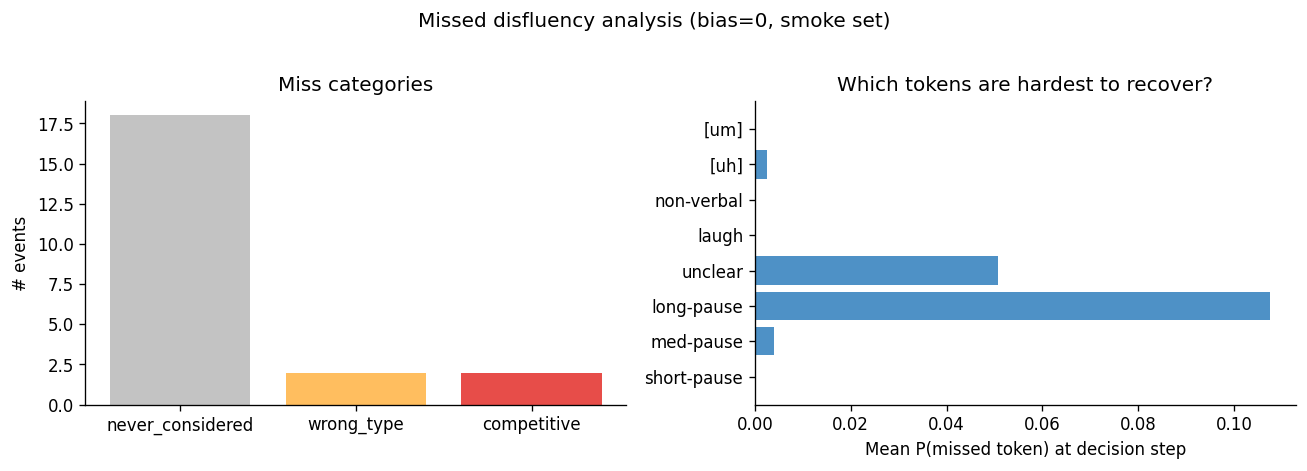

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

cat_counts = miss_df["category"].value_counts()
axes[0].bar(cat_counts.index, cat_counts.values, color=["#bdbdbd", "#ffb74d", "#e53935"], alpha=0.9)
axes[0].set_title("Miss categories"); axes[0].set_ylabel("# events")

by_tok = miss_df.groupby("ref_token")["prob_missed_token"].mean().reindex(DISFLUENCY_TOKENS)
axes[1].barh([TOKEN_SHORT[t] for t in DISFLUENCY_TOKENS], by_tok.values, color="#2f7ebc", alpha=0.85)
axes[1].set_xlabel("Mean P(missed token) at decision step")
axes[1].set_title("Which tokens are hardest to recover?")

plt.suptitle("Missed disfluency analysis (bias=0, smoke set)", y=1.02)
plt.tight_layout(); plt.show()

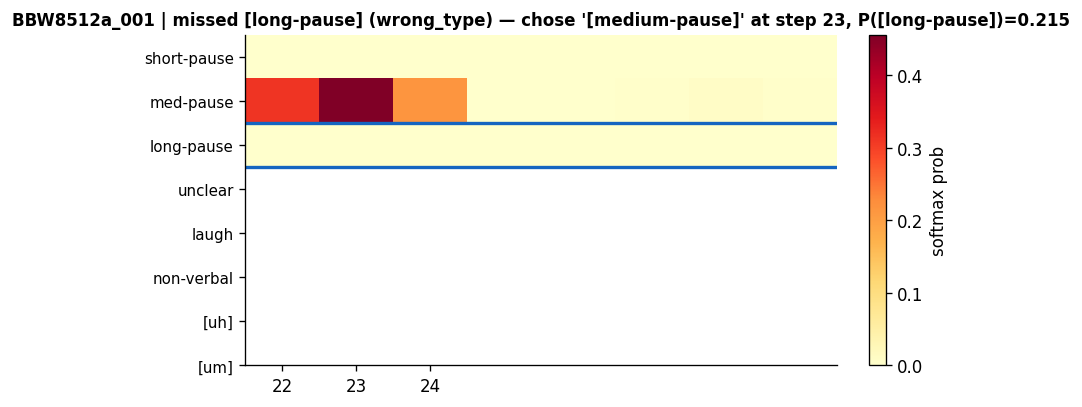

Reference context: to do. and [um] [long-pause] let's see [long-pause]


In [12]:
# Drill-down: top competitive miss — decode-step probability window
trace_lookup = {t["audio_path"]: t for t in traces}
top = miss_df.sort_values("prob_missed_token", ascending=False).iloc[0]
trace = trace_lookup[top["audio_path"]]
w0, w1, center = int(top["window_start"]), int(top["window_end"]), int(top["decode_step"])
window = [s for s in trace["steps"] if w0 - 1 <= s["step"] <= w1 + 1]

mat = np.array([[s["disfluency_probs"][tok] for tok in DISFLUENCY_TOKENS] for s in window])
fig, ax = plt.subplots(figsize=(max(7, len(window)), 3.5))
im = ax.imshow(mat, aspect="auto", cmap="YlOrRd", vmin=0, vmax=max(0.05, mat.max()))
ax.set_yticks(range(len(DISFLUENCY_TOKENS)))
ax.set_yticklabels([TOKEN_SHORT[t] for t in DISFLUENCY_TOKENS], fontsize=9)
ax.set_xticks(range(len(window)))
ax.set_xticklabels([s["step"] for s in window])
ref_tok = top["ref_token"]
if ref_tok in DISFLUENCY_TOKENS:
    ax.axhline(DISFLUENCY_TOKENS.index(ref_tok) - 0.5, color="#1565C0", lw=2)
    ax.axhline(DISFLUENCY_TOKENS.index(ref_tok) + 0.5, color="#1565C0", lw=2)
ax.set_title(
    f"{top['audio']} | missed {ref_tok} ({top['miss_type']}) — chose {top['chosen_token']!r} "
    f"at step {center}, P({ref_tok})={top['prob_missed_token']:.3f}", fontweight="bold", fontsize=10
)
plt.colorbar(im, ax=ax, fraction=0.04, label="softmax prob")
plt.tight_layout(); plt.show()

ri = int(top["ref_index"])
words = refs[top["audio_path"]].split()
print("Reference context:", " ".join(words[max(0, ri-4):ri+5]))

### Inference-level interpretation (links to report error analysis)

The miss trace above explains *why* held-out disfluency F1 lags train F1:

- **`never_considered` dominates** — at the missed disfluency's decision step, P(token) ≈ 0. The model produces **cleaner transcripts than the reference**, dropping pauses and non-verbal events when surrounding speech stays intelligible (report §Appendix).
- **`competitive` misses** — a minority of events where the correct bracket had non-trivial probability but lost to another token (e.g. `[long-pause]` vs `[medium-pause]`), matching the report's **pause duration conflation** failure mode.
- **`wrong_type`** — some disfluency mass at the step, but assigned to a different bracket (often another pause tier).
- Logit bias on the smoke set did not change metrics — consistent with most misses being **acoustic/recall failures**, not threshold issues at decode time.

## 7 · Key takeaways (transcription & inference)

**Data & parsing**
- Speaker-disjoint 826-clip corpus with ~10% disfluency tokens; heavy `[uh]` / `[unclear-speech]` frequency vs rare `[laughter]` / `[non-verbal]` motivates weighted and focal losses.

**Team transcription (final report)**
- Best model: WER **0.334**, count F1 **0.572**, OA-F1 **0.422** — beats prompted Qwen2-Audio and external ASR while emitting clinically meaningful brackets.
- Progressive ablations: full encoder LoRA > LLM-only; data augmentation + inverse weighting gives the largest F1 jump; synthetic speech + focal loss yields best WER/OA-F1; MFA/CTC did not help.
- **Overfitting persists** (train F1 ~0.94 vs test ~0.57) — data scarcity, not output format, is the limiting factor.

**My DoRA run & decode analysis**
- DoRA confirms the pattern: large train–test gap, fillers learned best, pause/rare tokens lag; order-aware F1 (~0.33 test) trails count F1 (~0.45).
- Inference tracing shows misses are mostly **under-prediction** (never considered), with occasional competitive pause-tier confusion — aligning with the report's qualitative error taxonomy.
- Decode-time logit bias is a cheap lever but insufficient when the model never assigns mass to the target token.

**Open question for QA (next section)**
**Open question for QA (next section)**
- Improved transcription has **not yet** translated into stronger audio reasoning; count-style disfluency questions remain the hardest benchmark slice.


## 8 · Audio QA evaluation

672 LLM-generated QA pairs (168 count · 168 multiple-choice · 336 yes/no) evaluated on the **base** Qwen2-Audio checkpoint under three input modes — mirroring Table tab:qa in the final report:

| Condition | Input to model |
|---|---|
| **Audio only** | Raw clip |
| **Audio + gold transcript** | Clip + reference (human) transcript |
| **Audio + finetuned transcript** | Clip + best team LoRA transcription |

Metrics in `ananya_data/qa_results/`. Content questions (~50%) test literal comprehension; disfluency questions probe pause/filler awareness and exact counting.


In [13]:
QA_DIR = DATA_DIR / "qa_results"
QA_RUNS = {
    "audio only": QA_DIR / "metrics_base_single.json",
    "audio + gold transcript": QA_DIR / "metrics_base_gold_transcripts.json",
    "audio + finetuned transcript": QA_DIR / "metrics_base_with_finetuned_transcripts.json",
}

qa = {label: json.loads(path.read_text(encoding="utf-8")) for label, path in QA_RUNS.items()}

overall_rows = []
detail_rows = []
for label, m in qa.items():
    overall_rows.append({
        "input mode": label,
        "n": m["num_evaluated"],
        "accuracy": m["overall_accuracy"],
        "mean score": m["overall_mean_score"],
        "content acc": m["by_category"]["content"]["accuracy"],
        "disfluency acc": m["by_category"]["disfluency"]["accuracy"],
    })
    for qtype in ("yes_no", "multiple_choice", "count"):
        stats = m["by_type"][qtype]
        detail_rows.append({
            "input mode": label,
            "question type": qtype,
            "accuracy": stats["accuracy"],
            **({"off-by-one acc": stats["off_by_one_accuracy"]} if qtype == "count" else {}),
        })

qa_overall = pd.DataFrame(overall_rows).set_index("input mode")
qa_detail = pd.DataFrame(detail_rows)

display(qa_overall.style.format({
    c: "{:.1%}" for c in qa_overall.columns if c != "n"
}).background_gradient(subset=["accuracy", "disfluency acc"], cmap="RdYlGn", vmin=0.3, vmax=0.8))

display(qa_detail.pivot(index="question type", columns="input mode", values="accuracy").style.format("{:.1%}"))

,n,accuracy,mean score,content acc,disfluency acc
input mode,,,,,
audio only,672,57.1%,61.8%,78.9%,35.4%
audio + gold transcript,672,57.3%,61.4%,77.1%,37.5%
audio + finetuned transcript,672,53.7%,58.3%,74.1%,33.3%


input mode,audio + finetuned transcript,audio + gold transcript,audio only
question type,,,
count,8.9%,9.5%,22.0%
multiple_choice,70.2%,72.0%,69.6%
yes_no,67.9%,73.8%,68.5%


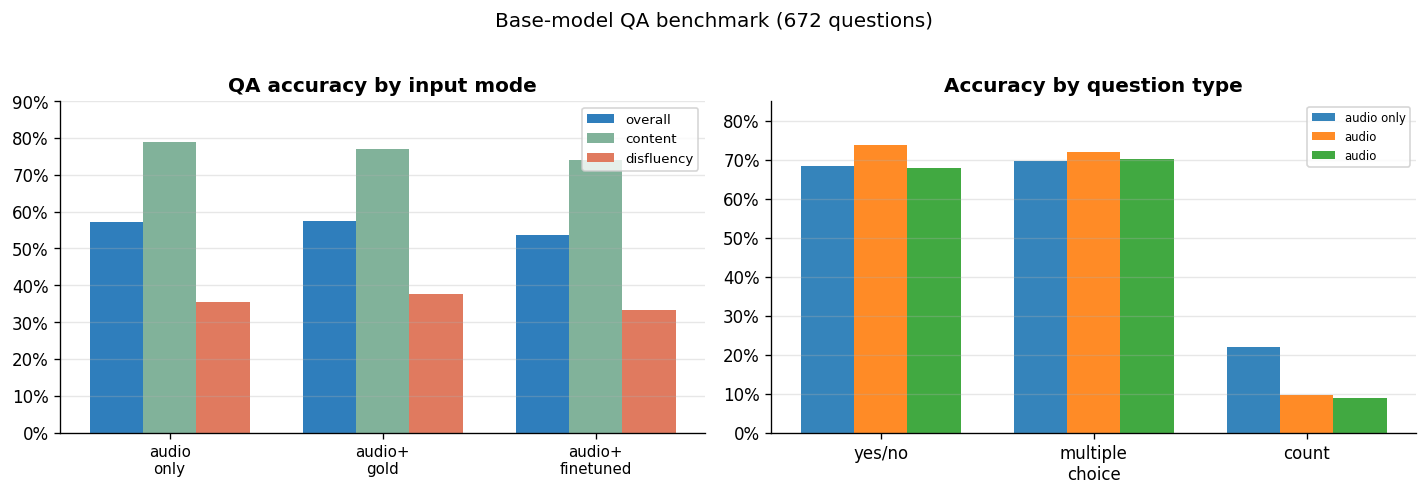

In [14]:
labels = list(qa.keys())
x = np.arange(len(labels))
w = 0.25

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: overall vs disfluency accuracy
overall = [qa[l]["overall_accuracy"] for l in labels]
disfl = [qa[l]["by_category"]["disfluency"]["accuracy"] for l in labels]
content = [qa[l]["by_category"]["content"]["accuracy"] for l in labels]

axes[0].bar(x - w, overall, w, label="overall", color="#2f7ebc")
axes[0].bar(x, content, w, label="content", color="#81b29a")
axes[0].bar(x + w, disfl, w, label="disfluency", color="#e07a5f")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["audio\nonly", "audio+\ngold", "audio+\nfinetuned"], fontsize=9)
axes[0].set_ylim(0, 0.9)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
axes[0].set_title("QA accuracy by input mode", fontweight="bold")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.3)

# right: accuracy by question type (grouped)
qtypes = ["yes_no", "multiple_choice", "count"]
x2 = np.arange(len(qtypes))
for i, label in enumerate(labels):
    vals = [qa[label]["by_type"][qt]["accuracy"] for qt in qtypes]
    axes[1].bar(x2 + (i - 1) * w, vals, w, label=label.split(" +")[0], alpha=0.9)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(["yes/no", "multiple\nchoice", "count"])
axes[1].set_ylim(0, 0.85)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
axes[1].set_title("Accuracy by question type", fontweight="bold")
axes[1].legend(fontsize=7, loc="upper right")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Base-model QA benchmark (672 questions)", y=1.02)
plt.tight_layout()
plt.show()

## 9 · QA insights (aligned with final report)

| Finding | Evidence in this notebook |
|---|---|
| **Content QA is relatively strong** | Yes/no + multiple-choice accuracy ≈ **69–79%** even without transcripts — the base model understands narrative content from audio alone. |
| **Disfluency QA is much harder** | Disfluency-category accuracy ≈ **35%** (audio-only) vs content ≈ **79%**; count questions (exact tallies) reach only **22%**. |
| **Gold transcripts barely help overall** | Overall accuracy 57.1% → 57.3%; marginal gain does not justify treating transcription and QA as independent stages. |
| **Transcripts hurt count questions** | Count accuracy **22% → 9.5%** with gold text — the model appears to **conflate bracket tokens with ordinary words** when they appear in context. |
| **Fine-tuned transcripts hurt further** | Overall **53.7%**; finetuned transcript mode underperforms gold on every slice, consistent with **error propagation** from imperfect disfluency transcription. |

**Conclusion (report §Question-Answer):** preserving disfluencies in transcription is necessary but **not sufficient** for diagnostic reasoning. Reliable dementia-aware QA likely requires **joint optimization** of transcription fidelity and question answering, not a sequential pipeline. Future work should prioritize more labeled dementia speech to close the generalization gap identified in both transcription and QA evaluations.